In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)
from scipy.stats import binomtest

os.makedirs("relatorio/figuras", exist_ok=True)   # pasta das figuras do relatório


## 1. Dados
Base do CDC (OpenML): 253 680 pessoas, 21 atributos inteiros e sem faltantes. O alvo é `1` para diabetes e `0` para sem diabetes. Só 13,9% são diabéticos, então um modelo que sempre responde "sem diabetes" já acerta 86,1%.

In [2]:
# Carregar: a base vem do OpenML (já está em cache na pasta dados/)
cdc = fetch_openml(data_id=46841, as_frame=True, parser="liac-arff", data_home="dados")
X = cdc.data
y = cdc.target.astype(int)   # o alvo vem como texto ('0', '1'); as métricas precisam do número 1

In [3]:
print(X.shape)                      # esperado: (253680, 21)
print(X.isna().sum().sum())         # esperado: 0 (sem faltantes)
print(X.dtypes.unique())            # esperado: só tipos inteiros

(253680, 21)
0
[dtype('int64')]


In [4]:
# Estatísticas descritivas (Tabela I, parte do CDC): a base inteira, antes da divisão
cols = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Income"]

desc = X[cols].describe().T[["mean", "std", "min", "max"]]
desc["var"] = X[cols].var()
desc = desc[["mean", "std", "var", "min", "max"]].round(2)
print(desc)   # esperado: BMI média 28,38, desvio 6,61, faixa 12-98; MentHlth média 3,18, variância 54,95

           mean   std    var   min   max
BMI       28.38  6.61  43.67  12.0  98.0
GenHlth    2.51  1.07   1.14   1.0   5.0
MentHlth   3.18  7.41  54.95   0.0  30.0
PhysHlth   4.24  8.72  76.00   0.0  30.0
Age        8.03  3.05   9.33   1.0  13.0
Income     6.05  2.07   4.29   1.0   8.0


In [5]:
# Proporção das classes: um modelo que sempre responde "sem diabetes" já acerta 86,1%
print(y.value_counts(normalize=True).round(3))   # esperado: 0 -> 0,861 e 1 -> 0,139

Diabetes_binary
0    0.861
1    0.139
Name: proportion, dtype: float64


## 2. Divisão
Cada linha é uma pessoa diferente, então o `train_test_split` comum é o correto (estratificado, para manter os 13,9% de diabéticos nos dois lados). SVM e kNN treinam em subamostras do treino, porque ficam lentos com 200 mil linhas; o teste é o mesmo para todos.

In [6]:
# Divisão: cada linha é uma pessoa diferente, então o train_test_split comum é o correto
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(len(X_treino), len(X_teste))   # esperado: 202944 50736
print(y_teste.sum())                 # esperado: 7069 diabéticos no teste

# predições de cada modelo no teste (a significância vai usar)
preds = {}

202944 50736
7069


In [7]:
# Subamostras estratificadas do treino (mantêm os 13,9% de diabéticos)
# SVM: 20 000 linhas
X_svm, _, y_svm, _ = train_test_split(X_treino, y_treino, train_size=20000,
                                      stratify=y_treino, random_state=42)

# kNN: 50 000 linhas
X_knn, _, y_knn, _ = train_test_split(X_treino, y_treino, train_size=50000,
                                      stratify=y_treino, random_state=42)

# Regressão logística: o treino inteiro (X_treino, y_treino)
# O teste continua o mesmo para todos (50 736 linhas): só o treino é reduzido.

print(len(X_svm), round(y_svm.mean(), 3))   # esperado: 20000 e ~0,139
print(len(X_knn), round(y_knn.mean(), 3))   # esperado: 50000 e ~0,139

20000 0.139
50000 0.139


## 3. Modelos sem pesos
Mesma estrutura do Mice (`Pipeline` + `GridSearchCV`), com validação cruzada comum, porque cada linha é uma pessoa diferente. Cada modelo treina no seu conjunto (SVM em 20 000 linhas, kNN em 50 000 e regressão logística no treino inteiro) e todos são avaliados no mesmo teste. A métrica é a da classe 1 (diabetes): precisão, revocação e F1.

In [8]:
# SVM linear (sem pesos)
pipe = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="linear")),
])

grade = {"modelo__C": [0.1, 1, 10]}

gs_svm_lin = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro", n_jobs=-1)
gs_svm_lin.fit(X_svm, y_svm)

pred = gs_svm_lin.predict(X_teste)
print(gs_svm_lin.best_params_)
print("CV f1_macro:", round(gs_svm_lin.best_score_, 3))
print("Acurácia:", round(accuracy_score(y_teste, pred), 3))
print("Precisão:", round(precision_score(y_teste, pred, zero_division=0), 3))
print("Revocação:", round(recall_score(y_teste, pred), 3))
print("F1:", round(f1_score(y_teste, pred), 3))

{'modelo__C': 0.1}
CV f1_macro: 0.463
Acurácia: 0.861
Precisão: 0.0
Revocação: 0.0
F1: 0.0


In [9]:
# SVM RBF (sem pesos)
pipe = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="rbf")),
])

grade = {"modelo__C": [0.1, 1, 10], "modelo__gamma": ["scale", 0.01, 0.1]}

gs_svm_rbf = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro", n_jobs=-1)
gs_svm_rbf.fit(X_svm, y_svm)

pred = gs_svm_rbf.predict(X_teste)
print(gs_svm_rbf.best_params_)
print("CV f1_macro:", round(gs_svm_rbf.best_score_, 3))
print("Acurácia:", round(accuracy_score(y_teste, pred), 3))
print("Precisão:", round(precision_score(y_teste, pred, zero_division=0), 3))
print("Revocação:", round(recall_score(y_teste, pred), 3))
print("F1:", round(f1_score(y_teste, pred), 3))

{'modelo__C': 10, 'modelo__gamma': 0.1}
CV f1_macro: 0.601
Acurácia: 0.846
Precisão: 0.399
Revocação: 0.21
F1: 0.275


In [10]:
# Regressão logística (sem pesos)
pipe = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=5000)),
])

grade = {"modelo__C": [0.01, 0.1, 1, 10]}

gs_lr = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro", n_jobs=-1)
gs_lr.fit(X_treino, y_treino)

pred = gs_lr.predict(X_teste)
print(gs_lr.best_params_)
print("CV f1_macro:", round(gs_lr.best_score_, 3))
print("Acurácia:", round(accuracy_score(y_teste, pred), 3))
print("Precisão:", round(precision_score(y_teste, pred, zero_division=0), 3))
print("Revocação:", round(recall_score(y_teste, pred), 3))
print("F1:", round(f1_score(y_teste, pred), 3))

{'modelo__C': 1}
CV f1_macro: 0.585
Acurácia: 0.862
Precisão: 0.517
Revocação: 0.158
F1: 0.242


In [11]:
# kNN (sem pesos)
pipe = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", KNeighborsClassifier()),
])

grade = {"modelo__n_neighbors": [1, 3, 5, 11, 21, 51]}

gs_knn = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro", n_jobs=-1)
gs_knn.fit(X_knn, y_knn)

pred = gs_knn.predict(X_teste)
print(gs_knn.best_params_)
print("CV f1_macro:", round(gs_knn.best_score_, 3), "±",
      round(gs_knn.cv_results_["std_test_score"][gs_knn.best_index_], 3))
print("Acurácia:", round(accuracy_score(y_teste, pred), 3))
print("Precisão:", round(precision_score(y_teste, pred, zero_division=0), 3))
print("Revocação:", round(recall_score(y_teste, pred), 3))
print("F1:", round(f1_score(y_teste, pred), 3))
print("F1 no treino (X_knn):", round(f1_score(y_knn, gs_knn.predict(X_knn), zero_division=0), 3))

{'modelo__n_neighbors': 3}
CV f1_macro: 0.593 ± 0.003
Acurácia: 0.837
Precisão: 0.367
Revocação: 0.237
F1: 0.288
F1 no treino (X_knn): 0.578


In [12]:
# Guardar as predições dos quatro modelos sem pesos
preds["SVM linear"] = gs_svm_lin.predict(X_teste)
preds["SVM RBF"] = gs_svm_rbf.predict(X_teste)
preds["Regressão logística"] = gs_lr.predict(X_teste)
preds["kNN"] = gs_knn.predict(X_teste)

## 4. Pesos balanceados
Com `class_weight="balanced"`, errar um diabético (cerca de 3,6) pesa cerca de 6 vezes mais que errar um saudável (cerca de 0,58). O modelo passa a aceitar mais alarmes falsos para encontrar os diabéticos: a revocação sobe, a precisão e a acurácia caem, e o F1 quase dobra. O kNN fica de fora, porque não tem `class_weight`.

In [13]:
# SVM linear (pesos balanceados)
pipe = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="linear", class_weight="balanced")),
])

grade = {"modelo__C": [0.1, 1, 10]}

gs_svm_lin_bal = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro", n_jobs=-1)
gs_svm_lin_bal.fit(X_svm, y_svm)

pred = gs_svm_lin_bal.predict(X_teste)
preds["SVM linear bal"] = pred
print(gs_svm_lin_bal.best_params_)
print("CV f1_macro:", round(gs_svm_lin_bal.best_score_, 3), "±",
      round(gs_svm_lin_bal.cv_results_["std_test_score"][gs_svm_lin_bal.best_index_], 3))
print("Acurácia:", round(accuracy_score(y_teste, pred), 3))
print("Precisão:", round(precision_score(y_teste, pred, zero_division=0), 3))
print("Revocação:", round(recall_score(y_teste, pred), 3))
print("F1:", round(f1_score(y_teste, pred), 3))

{'modelo__C': 1}
CV f1_macro: 0.62 ± 0.008
Acurácia: 0.712
Precisão: 0.298
Revocação: 0.786
F1: 0.432


In [14]:
# SVM RBF (pesos balanceados)
pipe = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="rbf", class_weight="balanced")),
])

grade = {"modelo__C": [0.1, 1, 10], "modelo__gamma": ["scale", 0.01, 0.1]}

gs_svm_rbf_bal = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro", n_jobs=-1)
gs_svm_rbf_bal.fit(X_svm, y_svm)

pred = gs_svm_rbf_bal.predict(X_teste)
preds["SVM RBF bal"] = pred
print(gs_svm_rbf_bal.best_params_)
print("CV f1_macro:", round(gs_svm_rbf_bal.best_score_, 3), "±",
      round(gs_svm_rbf_bal.cv_results_["std_test_score"][gs_svm_rbf_bal.best_index_], 3))
print("Acurácia:", round(accuracy_score(y_teste, pred), 3))
print("Precisão:", round(precision_score(y_teste, pred, zero_division=0), 3))
print("Revocação:", round(recall_score(y_teste, pred), 3))
print("F1:", round(f1_score(y_teste, pred), 3))
print("F1 no treino (X_svm):", round(f1_score(y_svm, gs_svm_rbf_bal.predict(X_svm), zero_division=0), 3))

{'modelo__C': 1, 'modelo__gamma': 0.1}
CV f1_macro: 0.631 ± 0.005
Acurácia: 0.745
Precisão: 0.305
Revocação: 0.649
F1: 0.415
F1 no treino (X_svm): 0.581


In [15]:
# Regressão logística (pesos balanceados)
pipe = Pipeline([
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=5000, class_weight="balanced")),
])

grade = {"modelo__C": [0.01, 0.1, 1, 10]}

gs_lr_bal = GridSearchCV(pipe, grade, cv=5, scoring="f1_macro", n_jobs=-1)
gs_lr_bal.fit(X_treino, y_treino)

pred = gs_lr_bal.predict(X_teste)
preds["Regressão logística bal"] = pred
print(gs_lr_bal.best_params_)
print("CV f1_macro:", round(gs_lr_bal.best_score_, 3), "±",
      round(gs_lr_bal.cv_results_["std_test_score"][gs_lr_bal.best_index_], 3))
print("Acurácia:", round(accuracy_score(y_teste, pred), 3))
print("Precisão:", round(precision_score(y_teste, pred, zero_division=0), 3))
print("Revocação:", round(recall_score(y_teste, pred), 3))
print("F1:", round(f1_score(y_teste, pred), 3))

{'modelo__C': 0.01}
CV f1_macro: 0.633 ± 0.002
Acurácia: 0.731
Precisão: 0.311
Revocação: 0.761
F1: 0.441


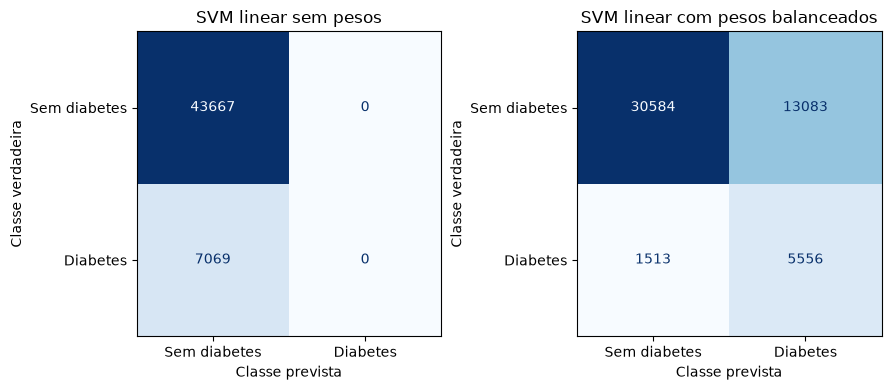

In [16]:
# Figura 1: SVM linear sem pesos x com pesos balanceados
rotulos = ["Sem diabetes", "Diabetes"]

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ConfusionMatrixDisplay.from_predictions(y_teste, preds["SVM linear"], ax=ax[0], colorbar=False,
                                        cmap="Blues", display_labels=rotulos)
ax[0].set_title("SVM linear sem pesos")
ax[0].set_xlabel("Classe prevista")
ax[0].set_ylabel("Classe verdadeira")

ConfusionMatrixDisplay.from_predictions(y_teste, preds["SVM linear bal"], ax=ax[1], colorbar=False,
                                        cmap="Blues", display_labels=rotulos)
ax[1].set_title("SVM linear com pesos balanceados")
ax[1].set_xlabel("Classe prevista")
ax[1].set_ylabel("Classe verdadeira")

plt.tight_layout()
plt.savefig("relatorio/figuras/cdc_matriz_svm_linear.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Bloco 4: bootstrap por linha (cada linha é uma pessoa independente)
nomes = ["SVM linear bal", "SVM RBF bal", "Regressão logística bal", "kNN"]
ref = "Regressão logística bal"

rng = np.random.RandomState(42)
n = len(y_teste)
y_arr = y_teste.to_numpy()

# o mesmo sorteio vale para os quatro modelos (bootstrap pareado)
f1_boot = {m: [] for m in nomes}
for _ in range(1000):
    idx = rng.randint(0, n, n)          # n posições, com reposição
    for m in nomes:
        f1_boot[m].append(f1_score(y_arr[idx], preds[m][idx], zero_division=0))

In [18]:
# Intervalos de 95% do F1 de cada modelo
for m in nomes:
    inf, sup = np.percentile(f1_boot[m], [2.5, 97.5])
    print(f"{m}: F1 = {f1_score(y_arr, preds[m]):.3f}  IC95% = [{inf:.3f}, {sup:.3f}]")

# Diferença pareada: cada modelo menos a regressão logística balanceada
print()
f1_ref = np.array(f1_boot[ref])
for m in nomes:
    if m == ref:
        continue
    dif = np.array(f1_boot[m]) - f1_ref
    inf, sup = np.percentile(dif, [2.5, 97.5])
    print(f"{m} - LR bal: IC95% = [{inf:.3f}, {sup:.3f}]")

SVM linear bal: F1 = 0.432  IC95% = [0.425, 0.440]
SVM RBF bal: F1 = 0.415  IC95% = [0.407, 0.424]
Regressão logística bal: F1 = 0.441  IC95% = [0.434, 0.449]
kNN: F1 = 0.288  IC95% = [0.277, 0.299]

SVM linear bal - LR bal: IC95% = [-0.011, -0.007]
SVM RBF bal - LR bal: IC95% = [-0.032, -0.021]
kNN - LR bal: IC95% = [-0.165, -0.142]


In [19]:
# McNemar: nos casos em que o modelo e a regressão logística discordam, um acerta mais que o outro?
ok_ref = preds[ref] == y_arr
for m in nomes:
    if m == ref:
        continue
    ok_m = preds[m] == y_arr
    b = int((ok_ref & ~ok_m).sum())    # só a regressão logística acertou
    c = int((ok_m & ~ok_ref).sum())    # só o outro modelo acertou
    p = binomtest(min(b, c), b + c, 0.5).pvalue
    print(f"{m}: b = {b}, c = {c}, p = {p:.1e}")

SVM linear bal: b = 1340, c = 367, p = 6.6e-130
SVM RBF bal: b = 3142, c = 3834, p = 1.2e-16
kNN: b = 4256, c = 9592, p = 0.0e+00


                         Acurácia  Precisão  Revocação     F1
SVM linear                  0.861     0.000      0.000  0.000
SVM RBF                     0.846     0.399      0.210  0.275
Regressão logística         0.862     0.517      0.158  0.242
kNN                         0.837     0.367      0.237  0.288
SVM linear bal              0.712     0.298      0.786  0.432
SVM RBF bal                 0.745     0.305      0.649  0.415
Regressão logística bal     0.731     0.311      0.761  0.441
Trivial (sempre 0)          0.861     0.000      0.000  0.000


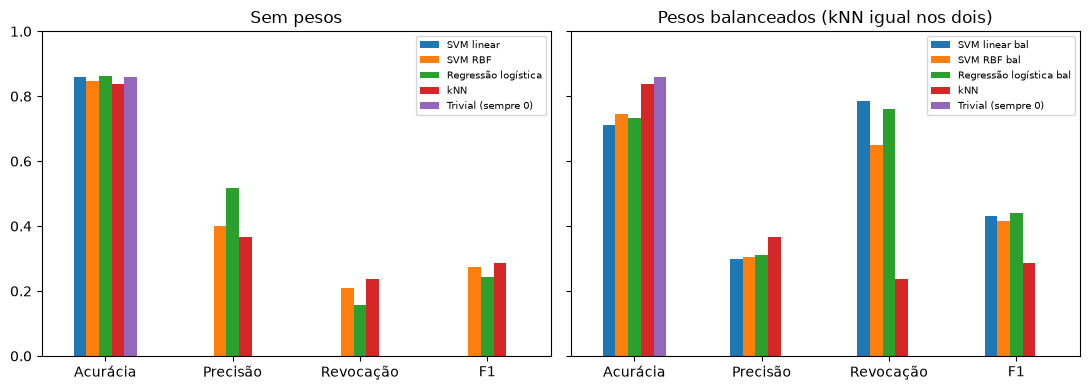

In [20]:
# Figura 5 (CDC): painel com as métricas da classe 1 de cada modelo no teste
linhas = {}
for m, p in preds.items():
    linhas[m] = {
        "Acurácia": accuracy_score(y_teste, p),
        "Precisão": precision_score(y_teste, p, zero_division=0),
        "Revocação": recall_score(y_teste, p),
        "F1": f1_score(y_teste, p),
    }
metricas = pd.DataFrame(linhas).T      # uma linha por modelo, uma coluna por métrica

# referência: o modelo que sempre responde "sem diabetes"
metricas.loc["Trivial (sempre 0)"] = [1 - y_teste.mean(), 0, 0, 0]
print(metricas.round(3))

sem_pesos = metricas.loc[["SVM linear", "SVM RBF", "Regressão logística", "kNN", "Trivial (sempre 0)"]]
balanceados = metricas.loc[["SVM linear bal", "SVM RBF bal", "Regressão logística bal", "kNN", "Trivial (sempre 0)"]]

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(11, 4))
sem_pesos.T.plot.bar(ax=ax[0])         # .T: métricas no eixo x, uma barra por modelo
balanceados.T.plot.bar(ax=ax[1])
ax[0].set_title("Sem pesos")
ax[1].set_title("Pesos balanceados (kNN igual nos dois)")
for a in ax:
    a.set_ylim(0, 1)
    a.tick_params(axis="x", rotation=0)
    a.legend(fontsize=7)
plt.tight_layout()
plt.savefig("relatorio/figuras/cdc_painel.png", dpi=150, bbox_inches="tight")
plt.show()